In [69]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from jaxopt import AndersonAcceleration
import pickle
import optax
from tqdm import trange

# Model parameters
m = 2  # Number of mitral neurons (glomeruli)
#x = jnp.ones(m)  # Input odour signal

#change x to be 0.5 arrray of size m
x = jnp.ones(m) * 0.5


n_r = 2.333
n_b = 0.9
n_y = 1.562

# Functions with different n values

In [70]:
# Naka-Rushton function

def nr(x, n):
    """Naka-Rushton activation function"""
    x = jnp.maximum(x, 0.0)
    return jnp.power(x, n) / (jnp.power(x, n) + 1)

In [71]:

def unpack_theta(theta, m):
    w_osn_r = jnp.array([theta[0], theta[0]])
    w_osn_b = jnp.array([theta[1], theta[1]])
    w_osn_g = jnp.array([theta[2], theta[2]])
    w_osn_y = jnp.array([theta[3], theta[3]])
    w_b_r = jnp.array([theta[4], theta[4]])
    w_b_g = jnp.array([theta[5], theta[5]])
    w_b_y = jnp.array([theta[6], theta[6]])
    w_r_y = jnp.array([theta[7], theta[7]])
    w_r_g = jnp.array([theta[8], theta[8]])
    alpha = jnp.array([theta[9], theta[9]])
    # Build 2x2 matrices so all elements are same type (avoids JAX shape error)
    zero = jnp.asarray(0.0)
    wr = jnp.asarray(theta[10])
    wy = jnp.asarray(theta[11])
    W_g_r = jnp.stack([jnp.stack([zero, wr]), jnp.stack([wr, zero])])
    W_g_y = jnp.stack([jnp.stack([zero, wy]), jnp.stack([wy, zero])])
    n_g_val = theta[12]
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, n_g_val


# Fixed-point function for green neurons with different n values
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g):
    """Fixed point equation for green neurons with different n values"""
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input, n=n_b)

    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input, n=n_r)

    g_input = w_osn_g * alpha * x - w_b_g * b_out + w_r_g * r_out
    g_new = nr(g_input, n=n_g)

    return g_new

# Solve fixed point via Anderson Acceleration with different n values
def solve_fixed_point(theta, x, m, n_r, n_b):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, n_g_val = unpack_theta(theta, m)
    g0 = jnp.zeros(m)

    # Pass n_g_val as explicit arg so JAX can differentiate w.r.t. it (closed-over values break custom_vjp)
    def fixed_point_with_n(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_g_val):
        return mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g_val)

    aa = AndersonAcceleration(fixed_point_with_n, history_size=5, tol=1e-10, maxiter=50)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_g_val)
    return solution.params

# Compute mitral output with different n values
def mitral_output(theta, x, m, n_r, n_b, n_y):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, n_g_val = unpack_theta(theta, m)

    g = solve_fixed_point(theta, x, m, n_r, n_b)
    b = nr(w_osn_b * alpha * x, n=n_b)
    r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)
    y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r, n=n_y)

    return r, g, b, y

In [72]:
# Load theta_opt from pickle file
theta_opt_file = 'Theta_opt/theta_opt_12_in_0.5_out_0.2_ng.pkl'
with open(theta_opt_file, 'rb') as f:
    theta_opt = pickle.load(f)

theta_opt = np.array(theta_opt)
initial_count = theta_opt.shape[0]  # Store initial count for summary
print(f"Loaded theta_opt with shape: {theta_opt.shape}")
print(f"Number of samples: {theta_opt.shape[0]}")
print(f"Number of parameters per sample: {theta_opt.shape[1]}")

Loaded theta_opt with shape: (12, 13)
Number of samples: 12
Number of parameters per sample: 13


# Stability check

In [73]:
# Define the dynamics function F(s, theta, x, m) with different n values
# State vector s = [r, g, y]
def F(s, theta, x, m, n_r=2.333, n_b=0.9, n_y=1.562):
    """
    Dynamics function that computes the next state from current state s.
    """
    # Unpack state vector
    r = s[:m]
    g = s[m:2*m]
    y = s[2*m:3*m]

    # Unpack parameters
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, n_g_val = unpack_theta(theta, m)

    # Compute b (doesn't depend on state, only on input)
    b = nr(w_osn_b * alpha * x, n=n_b)

    # Compute new r from current g
    r_new = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)

    # Compute new g from current r
    g_new = nr(w_osn_g * alpha * x - w_b_g * b + w_r_g * r, n=n_g_val)

    # Compute new y from g_new and r_new
    y_new = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g_new + w_r_y * r_new, n=n_y)

    # Return concatenated state vector
    s_prime = jnp.concatenate([r_new, g_new, y_new])
    return s_prime

# Compute Jacobian matrix J = dF/ds at the fixed point s_star
def compute_jacobian(F, s_star, theta, x, m, n_r, n_b, n_y):
    # Create a function that only depends on s (for JAX differentiation)
    def F_s(s):
        return F(s, theta, x, m, n_r, n_b, n_y)

    # jax.jacobian computes the Jacobian matrix: J[i,j] = dF_i/ds_j
    J = jax.jacobian(F_s)(s_star)
    return J

# Compute matrix A and check stability
def compute_stability(F, s_star, theta, x, m, tau=1.0, n_r=2.333, n_b=0.9, n_y=1.562):
    n = s_star.shape[0]
    I = jnp.eye(n)
    J = compute_jacobian(F, s_star, theta, x, m, n_r, n_b, n_y)
    A = (1 / tau) * (J - I)

    eigenvalues = jnp.linalg.eigvals(A)
    eigenvalues_np = np.array(eigenvalues)

    # Check stability - all eigenvalues must have negative real parts
    real_parts = np.real(eigenvalues_np)
    is_stable = np.all(real_parts < 0.0)

    return {
        'J': J,
        'A': A,
        'eigenvalues': eigenvalues_np,
        'is_stable': is_stable,
        'real_parts': real_parts,
        'imag_parts': np.imag(eigenvalues_np)
    }


In [74]:
# Use a subset of samples for faster analysis
n_samples_to_analyze = 13 #theta_opt.shape[0]
theta_subset = theta_opt[:n_samples_to_analyze]
print(f"\nUsing {n_samples_to_analyze} samples for analysis")


Using 13 samples for analysis


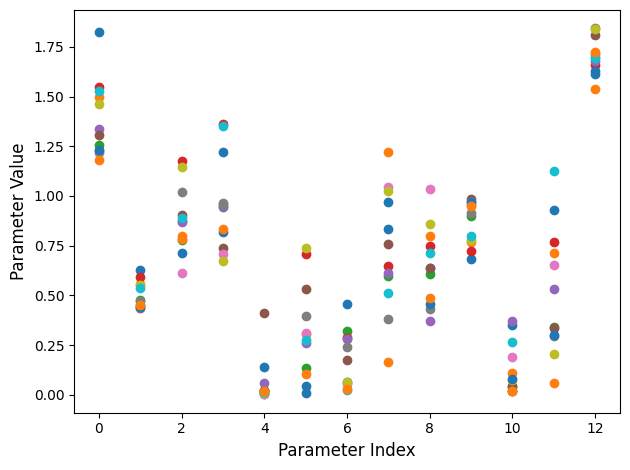

In [75]:
# raw values
for i in range(theta_opt.shape[0]):
    plt.plot(theta_opt[i, :], marker='o', linestyle=' ')
plt.xlabel('Parameter Index', fontsize=12)
plt.ylabel('Parameter Value', fontsize=12)
#plt.xlim(0,30)
plt.tight_layout()
plt.show()


# Compute Hessian

In [76]:
theta_opt[0]

array([1.825987  , 0.62825054, 0.8719196 , 1.2192127 , 0.00207622,
       0.01051686, 0.06425038, 0.9716879 , 0.63842887, 0.68224686,
       0.35236952, 0.9285551 , 1.611317  ], dtype=float32)

In [77]:
n_y

1.562

In [78]:
_th = theta_opt[0].copy()
display(mitral_output(_th, x, m, n_r, n_b, n_y))
_th[12] = 1.8
display(mitral_output(_th, x, m, n_r, n_b, n_y))


(Array([0.19999993, 0.19999993], dtype=float32),
 Array([0.19999996, 0.19999996], dtype=float32),
 Array([0.19999999, 0.19999999], dtype=float32),
 Array([0.19999994, 0.19999994], dtype=float32))

(Array([0.2053988, 0.2053988], dtype=float32),
 Array([0.17740627, 0.17740627], dtype=float32),
 Array([0.19999999, 0.19999999], dtype=float32),
 Array([0.21588154, 0.21588154], dtype=float32))

Processing 12 samples...
  Sample 1/12...
Completed processing 12 samples


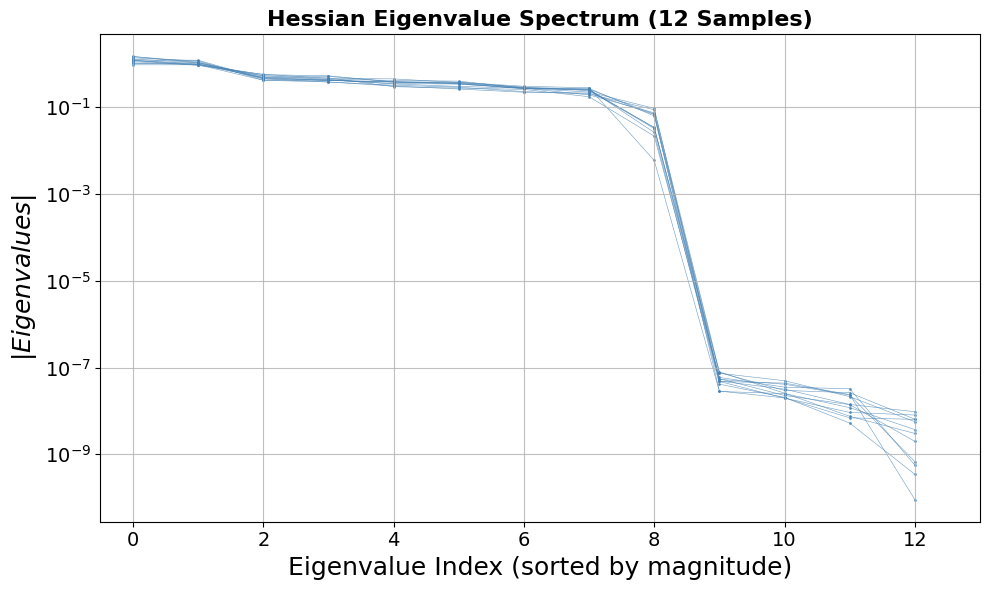

In [79]:
@jax.jit
def y_output_sum(theta):
    """Compute output y as a function of parameters"""
    r, g, b, y = mitral_output(theta, x, m, n_r, n_b, n_y)
    return jnp.sum(y)

grad = jax.jit(jax.grad(y_output_sum))
hessian = jax.jit(jax.jacrev(grad))

theta_samples = theta_opt
near_zero_threshold = 1e-5

print(f"Processing {theta_samples.shape[0]} samples...")
n_samples, n_params = theta_samples.shape[0], theta_samples.shape[1]
all_eigenvalues = np.zeros((n_samples, n_params))
all_eigenvectors = np.zeros((n_samples, n_params, n_params))

# Process all samples
for i in range(n_samples):
    if i % 100 == 0:
        print(f"  Sample {i+1}/{n_samples}...")

    theta_star = jnp.array(theta_samples[i, :])
    H = jnp.squeeze(hessian(theta_star))

    # Compute and sort eigenvalues in one step
    eigenvalues_H = np.array(jnp.linalg.eigh(H).eigenvalues)
    eigenvectors_H = np.array(jnp.linalg.eigh(H).eigenvectors)
    all_eigenvalues[i, :] = np.abs(eigenvalues_H[np.argsort(np.abs(eigenvalues_H))[::-1]])
    all_eigenvectors[i, :, :] = eigenvectors_H[:, np.argsort(np.abs(eigenvalues_H))[::-1]]

print(f"Completed processing {n_samples} samples")

# Visualise
fig, ax = plt.subplots(figsize=(10, 6))
n_params = all_eigenvalues.shape[1]

# Plot individual samples (light, transparent)
ax.semilogy(all_eigenvalues.T, 'o-', ms=1, lw=0.4, alpha=0.8, color='steelblue', zorder=1)

# Plot statistics
ax.set_xlabel('Eigenvalue Index (sorted by magnitude)', fontsize=18)
ax.set_ylabel('$|Eigenvalues|$', fontsize=18)
ax.set_xlim(-0.5, n_params)
ax.tick_params(axis='both', labelsize=14, direction='out')
ax.grid(True, alpha=0.8)
ax.set_title(f'Hessian Eigenvalue Spectrum ({n_samples} Samples)', fontsize=16, fontweight='bold')

plt.tight_layout()
plt.show()

In [80]:
all_eigenvectors.shape

(12, 13, 13)

In [81]:

threshold = 1e-1  # Threshold for near-zero eigenvalues

def get_subspace2_eigenvectors(sample_idx, all_eigenvalues, all_eigenvectors, threshold=1e-5):

    eigenvalues = all_eigenvalues[sample_idx, :]
    eigenvectors = all_eigenvectors[sample_idx, :, :]  # Shape: (n_params, n_params)

    # Find indices where eigenvalues < threshold
    near_zero_mask = eigenvalues < threshold
    n_near_zero = np.sum(near_zero_mask)

    # Extract corresponding eigenvectors (each column is an eigenvector)
    eigenvectors_subspace2 = eigenvectors[:, near_zero_mask].T  # Shape: (n_near_zero, n_params)

    return eigenvectors_subspace2

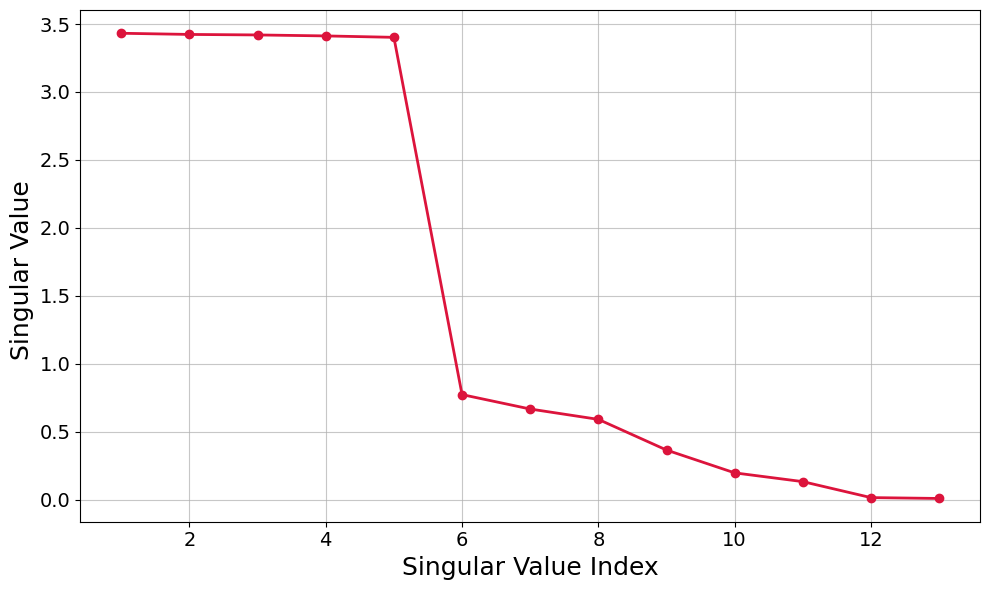

In [82]:

# Concatenate all near-zero eigenvectors from all samples
all_eigenvectors_subspace2 = []
for i in range(n_samples):
    vecs = get_subspace2_eigenvectors(i, all_eigenvalues, all_eigenvectors, threshold=threshold)
    all_eigenvectors_subspace2.append(vecs)
# Stack all (variable-sized, so use vstack)
eigenvectors_concat = np.vstack(all_eigenvectors_subspace2)  # Shape: (total_vectors, n_params)

# Perform SVD on concatenated eigenvectors
U, S, Vt = np.linalg.svd(eigenvectors_concat, full_matrices=False)

# Plot singular values vs index
plt.figure(figsize=(10, 6))
plt.plot(np.arange(1, len(S)+1), S, 'o-', color='crimson', lw=2, ms=6)
plt.xlabel('Singular Value Index', fontsize=18)
plt.ylabel('Singular Value ', fontsize=18)
plt.grid(True, alpha=0.7)
plt.tick_params(axis='both', labelsize=14)
plt.tight_layout()
plt.show()

In [83]:
Vt[:4].shape # orthonormal rows
Vt[:4].T.shape # orthonormal columns

(13, 4)

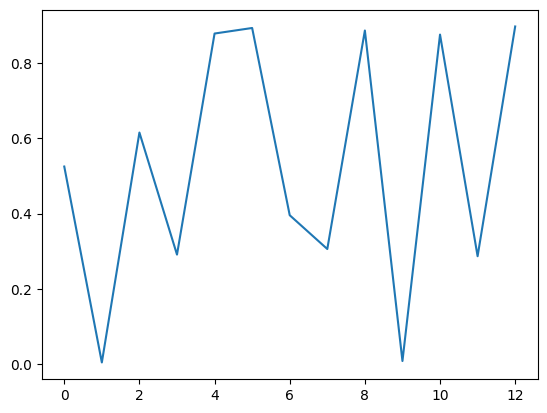

In [84]:
v_norm = np.linalg.norm(Vt[:5].T, axis=1)
plt.plot(v_norm)
plt.show()

invariant to rotation! 
no ng :(

In [85]:
def sparse_rotation(
    U, key, use_scheduler=True, scheduler_type='plateau', verbose=True
):

    def loss(qtilde):
        """Loss function: mean of absolute values of rotated u"""
        q, _ = jnp.linalg.qr(qtilde)
        u_rotated = U @ q
        return jnp.mean(jnp.abs(u_rotated))


    # Initialise Adam optimizer with learning rate scheduler
    key = jax.random.PRNGKey(key)
    key, subkey = jax.random.split(key)
    k = U.shape[1]  # Number of columns
    qtilde = jax.random.normal(subkey, (k, k))  # Fixed: should be (k, k) not (r, k)
    
    # Set up learning rate schedule
    if use_scheduler:
        if scheduler_type == 'cosine':
            # Cosine decay: more gradual reduction, keeps LR high for longer
            schedule = optax.cosine_decay_schedule(
                init_value=0.01,
                decay_steps=10000,  # Full decay over all iterations
                alpha=0.1  # Final LR will be 0.01 * 0.1 = 0.001
            )
            optimizer = optax.chain(
                optax.scale_by_adam(eps=1e-4),
                optax.scale_by_schedule(schedule)
            )
        elif scheduler_type == 'step':
            # Step decay: reduce LR at specific milestones (much later)
            schedule = optax.piecewise_constant_schedule(
                init_value=0.01,
                boundaries_and_scales={5000: 0.5, 8000: 0.5}  # Reduce by 0.5x at 5000 and 8000
            )
            optimizer = optax.chain(
                optax.scale_by_adam(eps=1e-4),
                optax.scale_by_schedule(schedule)
            )
        else:  # 'plateau' - reduce LR when loss plateaus
            # Start with fixed LR, will adjust manually
            schedule = None
            optimizer = optax.adam(learning_rate=0.01, eps=1e-4)
    else:
        schedule = None
        optimizer = optax.adam(learning_rate=0.01, eps=1e-4)
    
    opt_state = optimizer.init(qtilde)

    # Create value_and_grad function
    loss_value_and_grad = jax.value_and_grad(loss)

    # Track loss history
    loss_history = []
    n_iterations = 10000
    
    # For plateau scheduler: track best loss and patience
    if use_scheduler and scheduler_type == 'plateau':
        best_loss = float('inf')
        patience = 2000  # Wait 2000 iterations before reducing LR
        patience_counter = 0
        current_lr = 0.01
        lr_reduction_factor = 0.5
        min_lr = 0.0001

    # Optimization loop
    for iteration in range(n_iterations):
        loss_value, grads = loss_value_and_grad(qtilde)
        
        # For plateau scheduler: check if we should reduce LR
        if use_scheduler and scheduler_type == 'plateau':
            if loss_value < best_loss:
                best_loss = float(loss_value)
                patience_counter = 0
            else:
                patience_counter += 1
                
            if patience_counter >= patience and current_lr > min_lr:
                current_lr = max(current_lr * lr_reduction_factor, min_lr)
                # Reinitialize optimizer with new LR
                optimizer = optax.adam(learning_rate=current_lr, eps=1e-4)
                opt_state = optimizer.init(qtilde)
                patience_counter = 0
                if verbose:
                    print(f"  Reduced LR to {current_lr:.6f} at iteration {iteration}")
        
        updates, opt_state = optimizer.update(grads, opt_state)
        qtilde = optax.apply_updates(qtilde, updates)
        
        # Track loss
        loss_history.append(float(loss_value))

        if iteration % 10000 == 0 and verbose:
            if use_scheduler and scheduler_type == 'plateau':
                lr_display = current_lr
            elif use_scheduler and schedule is not None:
                lr_display = schedule(iteration)
            else:
                lr_display = 0.01
            print(f"Iteration {iteration}, Loss: {float(loss_value):.8f}, LR: {lr_display:.6f}")

    # Get optimized q
    q_opt,_ = jnp.linalg.qr(qtilde)

    U_sparse = U @ q_opt
    return U_sparse, loss_value, loss_history

#U_sparse = sparse_rotation(Vt[:4].T)

In [86]:
# Vectorized version of sparse_rotation for parallelization
def sparse_rotation_vectorized(U, keys, use_scheduler=True, scheduler_type='plateau', n_iterations=10000):

    batch_size = keys.shape[0]
    k = U.shape[1]
    n = U.shape[0]
    
    def loss(qtilde):
        """Loss function: mean of absolute values of rotated u"""
        q, _ = jnp.linalg.qr(qtilde)
        u_rotated = U @ q
        return jnp.mean(jnp.abs(u_rotated))
    
    def optimize_single(key):
        """Optimize for a single initialization"""
        key, subkey = jax.random.split(key)
        qtilde = jax.random.normal(subkey, (k, k))
        
        # Set up optimizer
        if use_scheduler:
            if scheduler_type == 'cosine':
                schedule = optax.cosine_decay_schedule(
                    init_value=0.01,
                    decay_steps=n_iterations,
                    alpha=0.1
                )
                optimizer = optax.chain(
                    optax.scale_by_adam(eps=1e-4),
                    optax.scale_by_schedule(schedule)
                )
            elif scheduler_type == 'step':
                schedule = optax.piecewise_constant_schedule(
                    init_value=0.01,
                    boundaries_and_scales={5000: 0.5, 8000: 0.5}
                )
                optimizer = optax.chain(
                    optax.scale_by_adam(eps=1e-4),
                    optax.scale_by_schedule(schedule)
                )
            else:  # 'plateau' or default
                # For plateau, use fixed LR of 0.01
                # The original plateau scheduler keeps LR at 0.01 for most iterations
                # (reduces only when loss plateaus, typically after 3000+ iterations)
                # Using fixed 0.01 should give similar results since most optimization
                # happens at this LR anyway
                optimizer = optax.adam(learning_rate=0.01, eps=1e-4)
        else:
            optimizer = optax.adam(learning_rate=0.01, eps=1e-4)
        
        opt_state = optimizer.init(qtilde)
        loss_value_and_grad = jax.value_and_grad(loss)
        
        # Optimization loop - use scan for efficiency
        def step(carry, i):
            qtilde, opt_state = carry
            loss_value, grads = loss_value_and_grad(qtilde)
            updates, opt_state = optimizer.update(grads, opt_state)
            qtilde = optax.apply_updates(qtilde, updates)
            return (qtilde, opt_state), loss_value
        
        (qtilde_final, _), loss_history = jax.lax.scan(
            step, (qtilde, opt_state), jnp.arange(n_iterations)
        )
        
        # Get final Q
        q_opt, _ = jnp.linalg.qr(qtilde_final)
        U_sparse = U @ q_opt
        
        return U_sparse, loss_history[-1]
    
    # Vectorize over keys using vmap and JIT compile for speed
    optimize_batch = jax.jit(jax.vmap(optimize_single))
    
    # Process all keys in parallel (JIT compilation happens on first call)
    U_sparse_batch, loss_values = optimize_batch(keys)
    
    return U_sparse_batch, loss_values

In [87]:
# PARALLELIZED VERSION - Use this instead
n_key = 1000
batch_size = 100  # Process in batches to manage memory

n, k = Vt[:5].T.shape

# Configuration
config = {'use_scheduler': True, 'scheduler_type': 'plateau', 'label': 'Plateau Scheduler'}

# Generate all random keys upfront
print(f"Generating {n_key} random keys...")
keys = jax.random.split(jax.random.PRNGKey(0), n_key)

# Process in batches for memory efficiency
print(f"Processing {n_key} initializations in batches of {batch_size}...")
U_sparse_all = []
loss_values_all = []

for batch_start in trange(0, n_key, batch_size):
    batch_end = min(batch_start + batch_size, n_key)
    batch_keys = keys[batch_start:batch_end]
    
    # Process batch in parallel using JAX vmap
    U_sparse_batch, loss_batch = sparse_rotation_vectorized(
        Vt[:5].T,
        batch_keys,
        use_scheduler=config['use_scheduler'],
        scheduler_type=config['scheduler_type'] if config['use_scheduler'] else None,
        n_iterations=10000
    )
    
    U_sparse_all.append(np.array(U_sparse_batch))
    loss_values_all.append(np.array(loss_batch))

# Concatenate results
U_sparse_coll = np.concatenate(U_sparse_all, axis=0)
loss_value_coll = np.concatenate(loss_values_all, axis=0)

print(f"\nCompleted! Processed {n_key} initializations.")
print(f"Loss range: [{loss_value_coll.min():.6f}, {loss_value_coll.max():.6f}]")
print(f"Mean loss: {loss_value_coll.mean():.6f}")


Generating 1000 random keys...
Processing 1000 initializations in batches of 100...


100%|██████████| 10/10 [00:22<00:00,  2.25s/it]


Completed! Processed 1000 initializations.
Loss range: [0.136787, 0.153871]
Mean loss: 0.139360


In [88]:
display(U_sparse_coll.shape)
display(loss_value_coll.shape)

(1000, 13, 5)

(1000,)

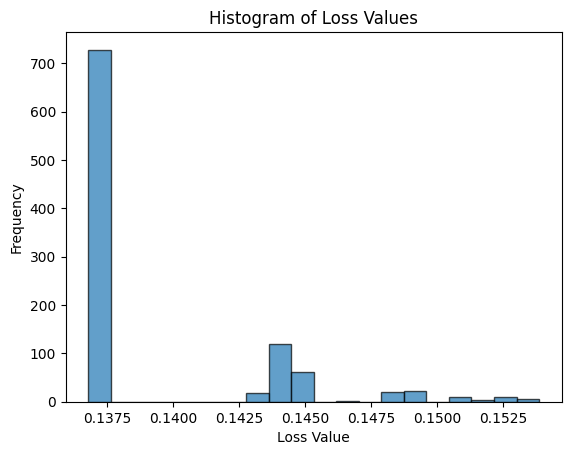

In [89]:
# plot histogram of loss values
plt.hist(loss_value_coll, bins=20, alpha=0.7, edgecolor='black')
plt.xlabel('Loss Value')
plt.ylabel('Frequency')
plt.title('Histogram of Loss Values')
plt.show()


In [90]:
# Isolate lowest-loss cluster and check subspace matching

from sklearn.cluster import KMeans

# =====================================================================
# Split all 1000 solutions into 3 broad clusters
# =====================================================================
kmeans3 = KMeans(n_clusters=3, random_state=0, n_init=10)
labels3 = kmeans3.fit_predict(loss_value_coll.reshape(-1, 1))
centroids3 = kmeans3.cluster_centers_.flatten()
best_cluster_id = np.argmin(centroids3)

best_mask_broad = labels3 == best_cluster_id
loss_broad = loss_value_coll[best_mask_broad]

print(f"3-cluster centroids (sorted): {np.sort(centroids3)}")
print(f"Broad lowest cluster: {best_mask_broad.sum()} solutions, "
      f"loss ∈ [{loss_broad.min():.6f}, {loss_broad.max():.6f}]")


3-cluster centroids (sorted): [0.13692187 0.14435701 0.15013093]
Broad lowest cluster: 728 solutions, loss ∈ [0.136787, 0.137114]


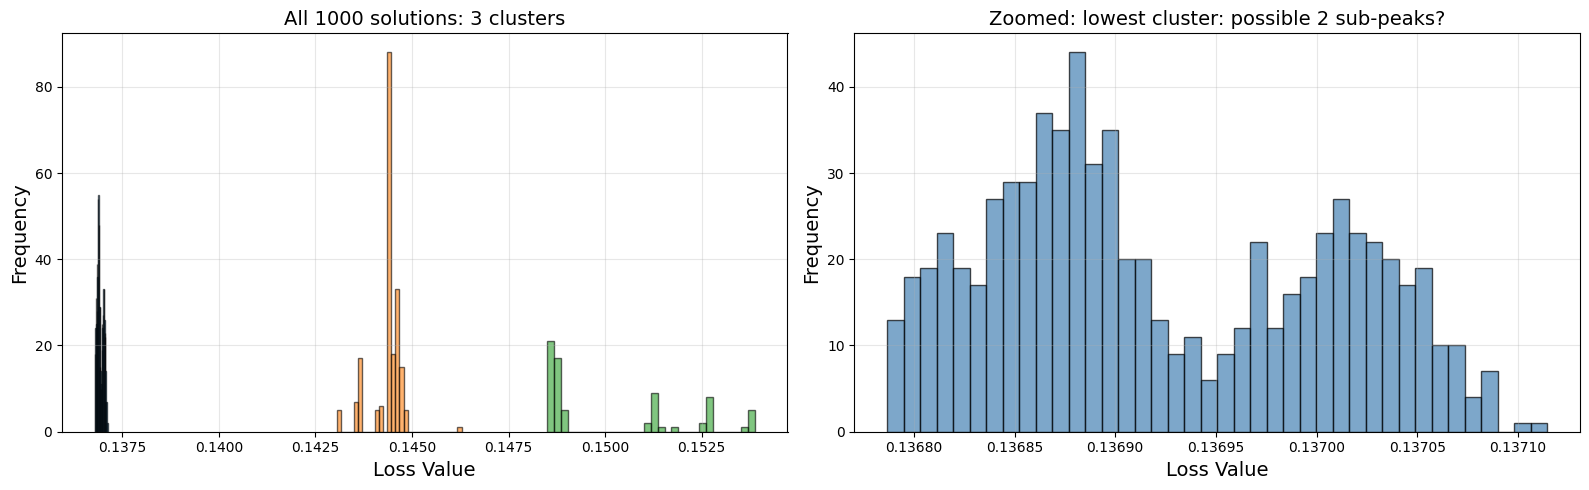

In [91]:
# =====================================================================
# Zoom into the lowest cluster (2 sub-peaks)
# =====================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# (a) Full histogram coloured by 3 clusters
for cid in range(3):
    mask = labels3 == cid
    axes[0].hist(loss_value_coll[mask], bins=30, alpha=0.6,
                 label=f'Cluster {cid} (n={mask.sum()}, c={centroids3[cid]:.4f})',
                 edgecolor='black')
axes[0].set_xlabel('Loss Value', fontsize=14)
axes[0].set_ylabel('Frequency', fontsize=14)
axes[0].set_title('All 1000 solutions: 3 clusters', fontsize=14)
axes[0].grid(True, alpha=0.3)

# (b) Zoomed histogram of lowest broad cluster 
axes[1].hist(loss_broad, bins=40, alpha=0.7, edgecolor='black', color='steelblue')
axes[1].set_xlabel('Loss Value', fontsize=14)
axes[1].set_ylabel('Frequency', fontsize=14)
axes[1].set_title('Zoomed: lowest cluster: possible 2 sub-peaks?', fontsize=14)
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Sub-cluster centroids: [0.13686338 0.13701329]
Lowest sub-peak: 444 solutions, loss ∈ [0.136787, 0.136938]


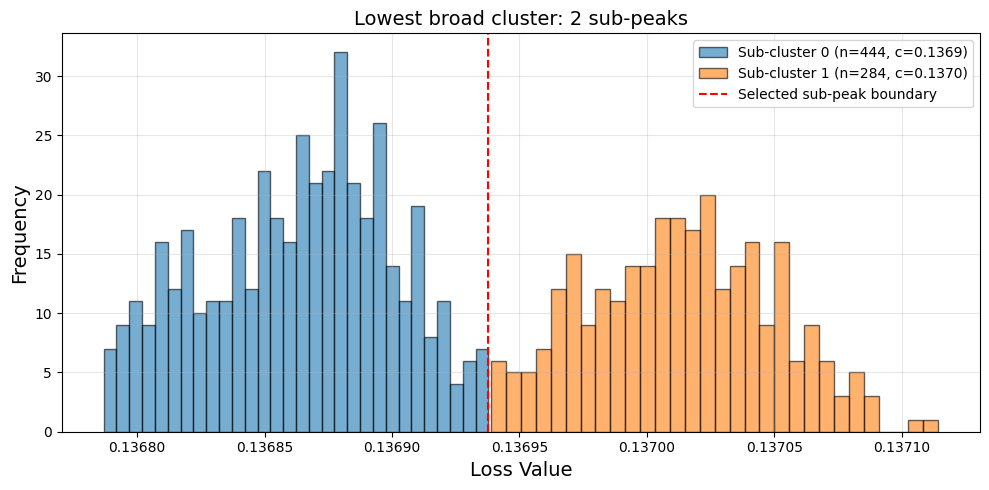

In [92]:
# =====================================================================
# Split the lowest broad cluster into 2 sub-clusters
# =====================================================================
kmeans2 = KMeans(n_clusters=2, random_state=0, n_init=10)
sub_labels = kmeans2.fit_predict(loss_broad.reshape(-1, 1))
sub_centroids = kmeans2.cluster_centers_.flatten()
best_sub_id = np.argmin(sub_centroids)

# Map back to original indices
broad_indices = np.where(best_mask_broad)[0]
sub_best_indices = broad_indices[sub_labels == best_sub_id]

U_best = U_sparse_coll[sub_best_indices]          # shape: (n_best, 12, 4)
loss_best = loss_value_coll[sub_best_indices]

print(f"\nSub-cluster centroids: {np.sort(sub_centroids)}")
print(f"Lowest sub-peak: {U_best.shape[0]} solutions, "
      f"loss ∈ [{loss_best.min():.6f}, {loss_best.max():.6f}]")

# Show zoomed histogram with the 2 sub-clusters colour-coded
fig, ax = plt.subplots(figsize=(10, 5))
for sid in range(2):
    sub_mask = sub_labels == sid
    ax.hist(loss_broad[sub_mask], bins=30, alpha=0.6,
            label=f'Sub-cluster {sid} (n={sub_mask.sum()}, c={sub_centroids[sid]:.4f})',
            edgecolor='black')
ax.axvline(loss_best.max(), color='red', ls='--', lw=1.5, label='Selected sub-peak boundary')
ax.set_xlabel('Loss Value', fontsize=14)
ax.set_ylabel('Frequency', fontsize=14)
ax.set_title('Lowest broad cluster: 2 sub-peaks', fontsize=14)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

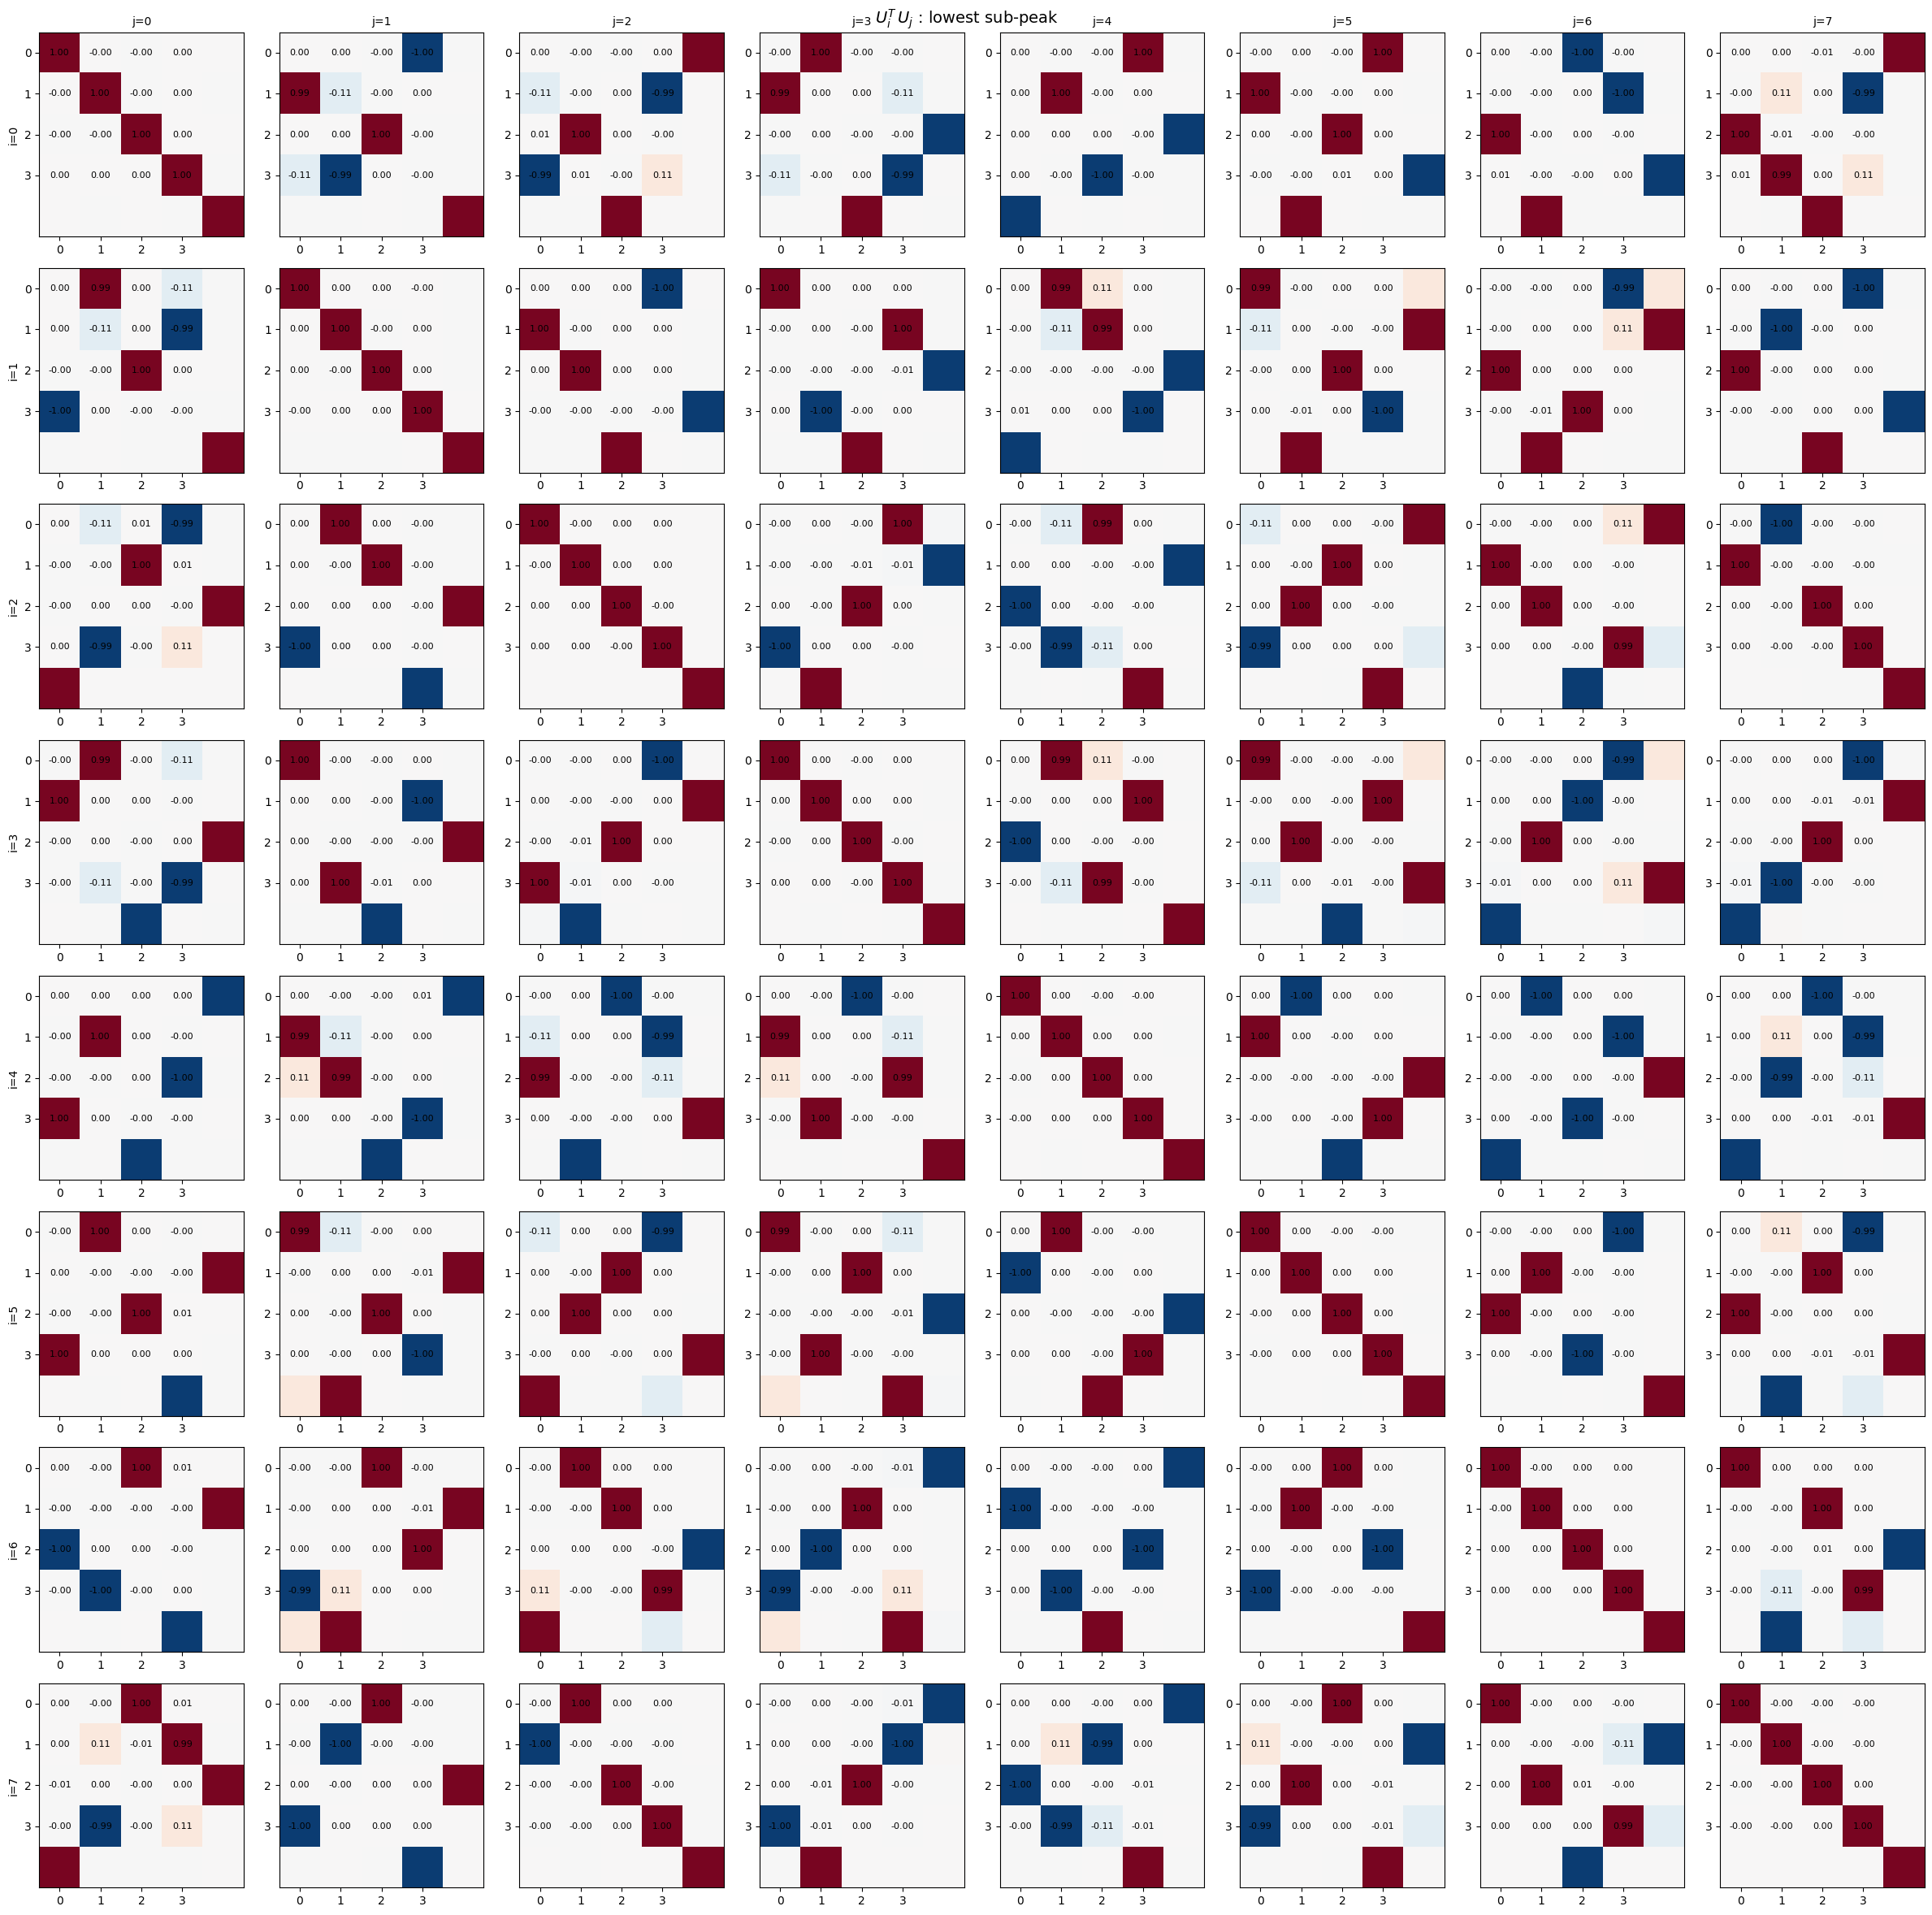

In [93]:
# =====================================================================
# Pairwise dot products  U_i^T @ U_j  for the lowest sub-peak
# =====================================================================
n_best = U_best.shape[0]
n_show = min(n_best, 8)

fig, axes_grid = plt.subplots(n_show, n_show, figsize=(3 * n_show, 3 * n_show))
for i in range(n_show):
    for j in range(n_show):
        P = U_best[i].T @ U_best[j]   # (4, 4)
        axes_grid[i, j].imshow(P, cmap='RdBu_r', vmin=-1.05, vmax=1.05)
        axes_grid[i, j].set_xticks(range(4))
        axes_grid[i, j].set_yticks(range(4))
        for ri in range(4):
            for ci in range(4):
                axes_grid[i, j].text(ci, ri, f'{P[ri, ci]:.2f}',
                                     ha='center', va='center', fontsize=8)
        if i == 0:
            axes_grid[i, j].set_title(f'j={j}', fontsize=10)
        if j == 0:
            axes_grid[i, j].set_ylabel(f'i={i}', fontsize=10)
plt.suptitle(r"$U_i^T \, U_j$ : lowest sub-peak ", fontsize=14)
plt.tight_layout()
plt.show()

In [94]:
# =====================================================================
# Quantitative signed-permutation check
# =====================================================================
max_off_perm = []
for i in range(n_best):
    for j in range(i + 1, n_best):
        P = U_best[i].T @ U_best[j]
        absP = np.abs(P)
        row_max = absP.max(axis=1)
        row_residual = absP.sum(axis=1) - row_max   # should be ~0
        max_off_perm.append(row_residual.max())

max_off_perm = np.array(max_off_perm)
print(f"\n── Signed permutation check ({n_best} solutions, "
      f"{len(max_off_perm)} pairs) ──")
print(f"Row residual (should be ~0):  mean={max_off_perm.mean():.4f},  "
      f"max={max_off_perm.max():.4f}")
#print(f"Pairs with residual < 0.10: {(max_off_perm < 0.10).mean():.1%}")
print(f"Pairs with residual < 0.05: {(max_off_perm < 0.05).mean():.1%}")
print(f"Pairs with residual < 0.01: {(max_off_perm < 0.01).mean():.1%}")


── Signed permutation check (444 solutions, 98346 pairs) ──
Row residual (should be ~0):  mean=0.0644,  max=0.1963
Pairs with residual < 0.05: 50.6%
Pairs with residual < 0.01: 25.9%


In [95]:
# Identify the two distinct sparse solutions and plot them

param_labels = [
    'w_osn_r', 'w_osn_b', 'w_osn_g', 'w_osn_y',
    'w_b_r', 'w_b_g', 'w_b_y',
    'w_r_y', 'w_r_g', 'alpha', 'W_g_r', 'W_g_y', 'n_g'
]

# Split U_best into 2 groups 
# Use solution 0 as reference: compute row residual of U_0^T @ U_j for all j
ref = U_best[0]  # (12, 4)
residuals = np.zeros(U_best.shape[0])
for j in range(U_best.shape[0]):
    P = ref.T @ U_best[j]
    absP = np.abs(P)
    row_max = absP.max(axis=1)
    residuals[j] = (absP.sum(axis=1) - row_max).max()

threshold = 0.05
group_A_mask = residuals < threshold
group_B_mask = ~group_A_mask

n_A, n_B = group_A_mask.sum(), group_B_mask.sum()
print(f"Group A (same as ref): {n_A} solutions")
print(f"Group B (different):   {n_B} solutions")

Group A (same as ref): 255 solutions
Group B (different):   189 solutions


In [96]:
# Sub-split Group B: use first Group B member as reference
U_B = U_best[group_B_mask]
ref_B = U_B[0]  # (12, 4)
residuals_B = np.zeros(U_B.shape[0])
for j in range(U_B.shape[0]):
    P = ref_B.T @ U_B[j]
    absP = np.abs(P)
    row_max = absP.max(axis=1)
    residuals_B[j] = (absP.sum(axis=1) - row_max).max()

threshold = 0.05
group_B1_mask = residuals_B < threshold
group_B2_mask = ~group_B1_mask

n_B1, n_B2 = group_B1_mask.sum(), group_B2_mask.sum()
print(f"Group B1 (same as ref_B): {n_B1} solutions")
print(f"Group B2 (different):     {n_B2} solutions")

Group B1 (same as ref_B): 187 solutions
Group B2 (different):     2 solutions


In [97]:
# Pick representative from each group (lowest loss within group) 
loss_A = loss_best[group_A_mask]
loss_B = loss_best[group_B_mask]
rep_A = U_best[group_A_mask][np.argmin(loss_A)]  # (12, 4)
rep_B = U_best[group_B_mask][np.argmin(loss_B)]  # (12, 4)

print(f"\nRepresentative A loss: {loss_A.min():.6f}")
print(f"Representative B loss: {loss_B.min():.6f}")

# Show the dot product between the two representatives
P_AB = rep_A.T @ rep_B
print(f"\nU_A^T @ U_B (should NOT be signed permutation):")
print(np.round(P_AB, 3))


Representative A loss: 0.136836
Representative B loss: 0.136787

U_A^T @ U_B (should NOT be signed permutation):
[[-0.113 -0.001  0.994  0.002 -0.   ]
 [ 0.002 -0.001 -0.001  1.    -0.002]
 [ 0.994  0.001  0.113 -0.002  0.001]
 [-0.001  1.     0.001  0.001  0.   ]
 [-0.001 -0.     0.     0.002  1.   ]]


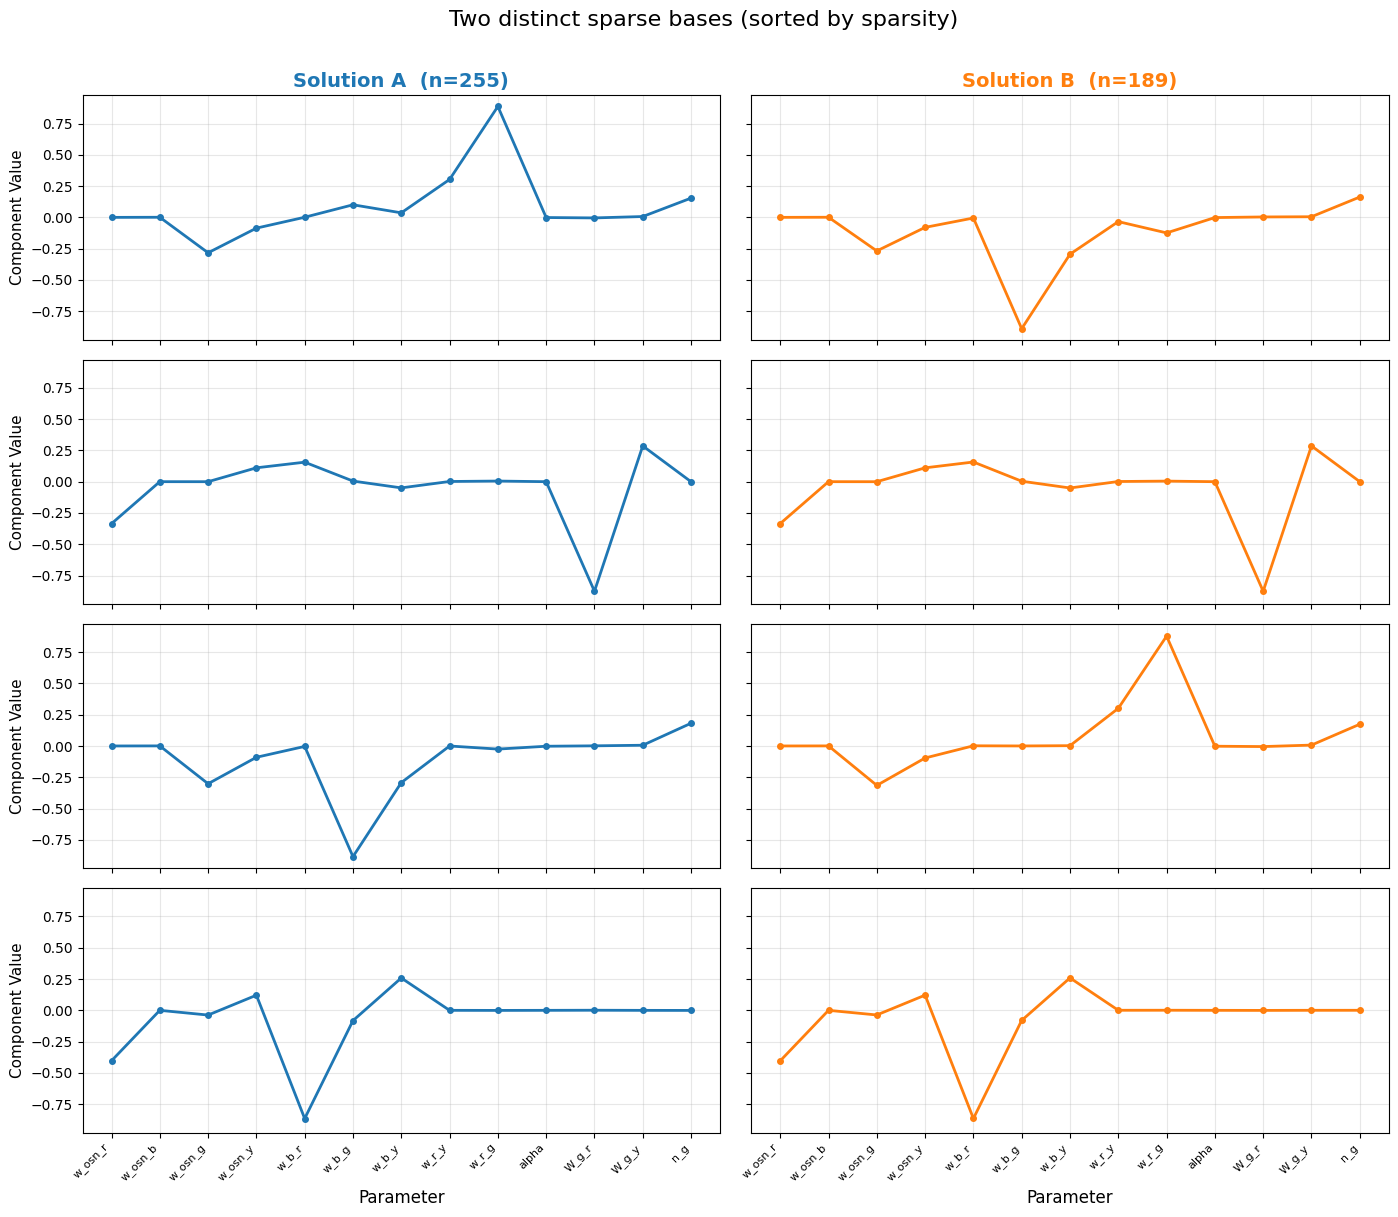

In [98]:
# Sort columns by sparsity 
def sort_by_sparsity(M):
    sums = np.abs(M).sum(0)
    order = np.argsort(sums)[::-1]
    return M[:, order], order

rep_A_sorted, order_A = sort_by_sparsity(rep_A)
rep_B_sorted, order_B = sort_by_sparsity(rep_B)

# Plot both solutions side by side 
fig, axes = plt.subplots(4, 2, figsize=(14, 12), sharex=True, sharey=True)

for i in range(4):
    # Group A
    axes[i, 0].plot(rep_A_sorted[:, i], '.-', color='tab:blue', lw=2, ms=8)
    axes[i, 0].set_xticks(range(len(param_labels)))
    axes[i, 0].set_xticklabels(param_labels, rotation=45, ha='right', fontsize=8)
    axes[i, 0].grid(True, alpha=0.3)
    axes[i, 0].set_ylabel('Component Value', fontsize=11)
    if i == 0:
        axes[i, 0].set_title(f'Solution A  (n={n_A})', fontsize=14, fontweight='bold', color='tab:blue')

    # Group B
    axes[i, 1].plot(rep_B_sorted[:, i], '.-', color='tab:orange', lw=2, ms=8)
    axes[i, 1].set_xticks(range(len(param_labels)))
    axes[i, 1].set_xticklabels(param_labels, rotation=45, ha='right', fontsize=8)
    axes[i, 1].grid(True, alpha=0.3)
    if i == 0:
        axes[i, 1].set_title(f'Solution B  (n={n_B})', fontsize=14, fontweight='bold', color='tab:orange')

axes[3, 0].set_xlabel('Parameter', fontsize=12)
axes[3, 1].set_xlabel('Parameter', fontsize=12)

plt.suptitle('Two distinct sparse bases (sorted by sparsity)', fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

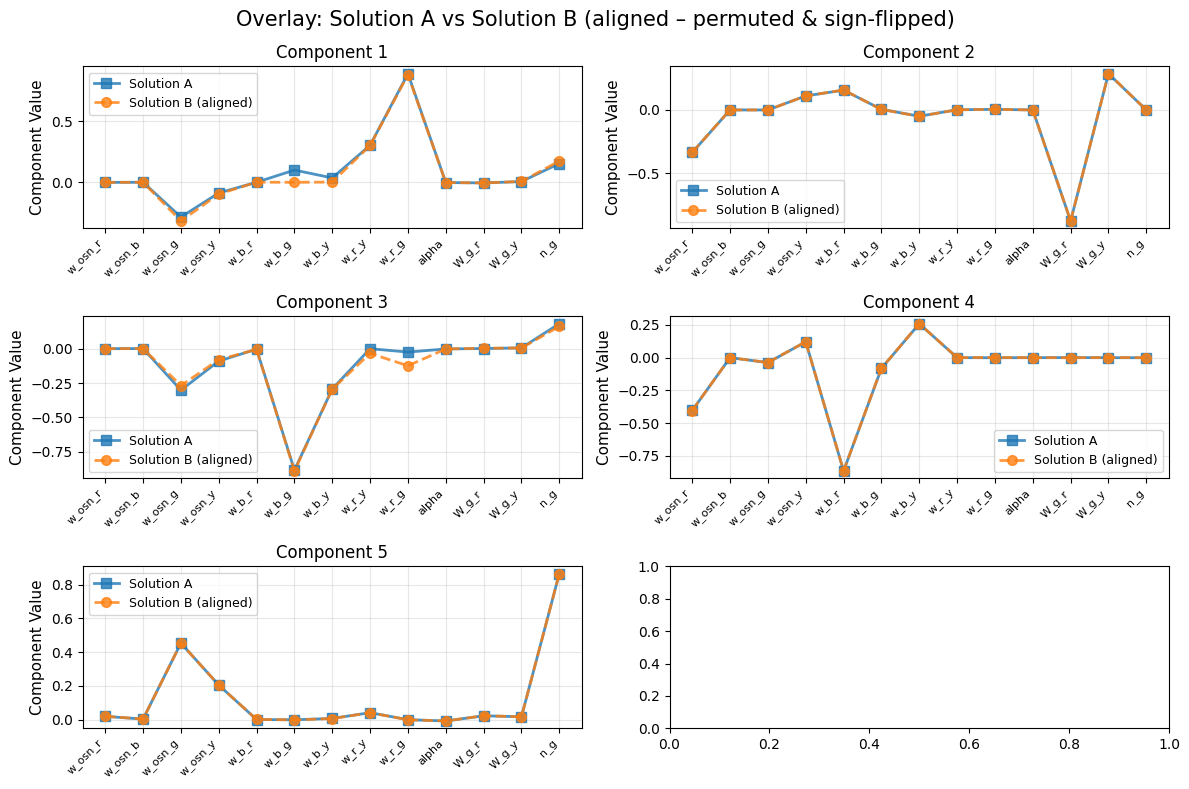


Sparsity pattern (entries with |value| > 0.1)

Solution A:
  Component 1: [('w_osn_g', '-0.283'), ('w_b_g', '0.100'), ('w_r_y', '0.303'), ('w_r_g', '0.886')]
  Component 2: [('w_osn_r', '-0.336'), ('w_osn_y', '0.111'), ('w_b_r', '0.156'), ('W_g_r', '-0.876'), ('W_g_y', '0.286')]
  Component 3: [('w_osn_g', '-0.302'), ('w_b_g', '-0.884'), ('w_b_y', '-0.293')]
  Component 4: [('w_osn_r', '-0.403'), ('w_osn_y', '0.121'), ('w_b_r', '-0.865'), ('w_b_y', '0.259')]

Solution B (aligned):
  Component 1: [('w_osn_g', '-0.315'), ('w_r_y', '0.301'), ('w_r_g', '0.878')]
  Component 2: [('w_osn_r', '-0.335'), ('w_osn_y', '0.111'), ('w_b_r', '0.157'), ('W_g_r', '-0.876'), ('W_g_y', '0.286')]
  Component 3: [('w_osn_g', '-0.268'), ('w_b_g', '-0.890'), ('w_b_y', '-0.294'), ('w_r_g', '-0.124')]
  Component 4: [('w_osn_r', '-0.404'), ('w_osn_y', '0.121'), ('w_b_r', '-0.864'), ('w_b_y', '0.259')]


In [99]:

# Align B to A (optimal permutation + sign flips) 
from scipy.optimize import linear_sum_assignment

# Compute cross-product between the sparsity-sorted versions
P = rep_A_sorted.T @ rep_B_sorted  # (4, 4)

# Hungarian algorithm: find permutation maximising sum of |P_ij|
# (linear_sum_assignment minimises cost, so negate)
row_ind, col_ind = linear_sum_assignment(-np.abs(P))

# Permute B's columns to match A's ordering
rep_B_aligned = rep_B_sorted[:, col_ind]

# Apply sign flips so each matched column has the same sign convention
signs = np.sign(np.array([P[r, c] for r, c in zip(row_ind, col_ind)]))
rep_B_aligned = rep_B_aligned * signs[None, :]


# Overlay – aligned comparison 
fig, axes2 = plt.subplots(3, 2, figsize=(12, 8))
axes2 = axes2.flatten()

for i in range(5):
    axes2[i].plot(rep_A_sorted[:, i], 's-', color='tab:blue', lw=2, ms=7,
                  label='Solution A', alpha=0.8)
    axes2[i].plot(rep_B_aligned[:, i], 'o--', color='tab:orange', lw=2, ms=7,
                  label='Solution B (aligned)', alpha=0.8)
    axes2[i].set_xticks(range(len(param_labels)))
    axes2[i].set_xticklabels(param_labels, rotation=45, ha='right', fontsize=8)
    axes2[i].grid(True, alpha=0.3)
    axes2[i].set_ylabel('Component Value', fontsize=11)
    axes2[i].set_title(f'Component {i+1}', fontsize=12)
    axes2[i].legend(fontsize=9)

plt.suptitle('Overlay: Solution A vs Solution B (aligned – permuted & sign-flipped)',
             fontsize=15)
plt.tight_layout()
plt.show()

# Print sparsity patterns (both using aligned B) 
print("\nSparsity pattern (entries with |value| > 0.1)")
for label, M_sorted in [("Solution A", rep_A_sorted), ("Solution B (aligned)", rep_B_aligned)]:
    print(f"\n{label}:")
    for col in range(4):
        nonzero_params = [(param_labels[row], f"{M_sorted[row, col]:.3f}")
                          for row in range(12) if abs(M_sorted[row, col]) > 0.1]
        print(f"  Component {col+1}: {nonzero_params}")

In [100]:
# save the 4 12x4 matrices

rep_A_sorted.shape
rep_B_aligned.shape

np.savez('reps_aligned_A.npz', rep_A_sorted=rep_A_sorted)
np.savez('reps_aligned_B.npz', rep_B_aligned=rep_B_aligned)

# Same analysis for the whole left cluster

In [101]:
# Same analysis but on the full left cluster (all 700 solutions) 

# U_broad and loss_broad come from the broad lowest cluster of the 3
U_broad = U_sparse_coll[best_mask_broad]       
loss_broad_all = loss_value_coll[best_mask_broad]

print(f"Full left cluster: {U_broad.shape[0]} solutions, "
      f"loss ∈ [{loss_broad_all.min():.6f}, {loss_broad_all.max():.6f}]")


Full left cluster: 728 solutions, loss ∈ [0.136787, 0.137114]


In [102]:
# How many distinct families are there? 
# Build a full pairwise distance matrix and cluster properly.

n_broad = U_broad.shape[0]
print(f"Computing {n_broad}×{n_broad} pairwise distance matrix...")

# Distance = max row residual (0 = same family, >0 = different)
dist_matrix = np.zeros((n_broad, n_broad))
for i in range(n_broad):
    for j in range(i + 1, n_broad):
        P = U_broad[i].T @ U_broad[j]
        absP = np.abs(P)
        row_max = absP.max(axis=1)
        d = (absP.sum(axis=1) - row_max).max()
        dist_matrix[i, j] = d
        dist_matrix[j, i] = d
        

# Connected components with threshold 
# Two solutions are "same family" if distance < threshold
threshold = 0.05
adjacency = (dist_matrix < threshold).astype(int)
np.fill_diagonal(adjacency, 1)


# Find connected components via BFS
visited = np.zeros(n_broad, dtype=bool)
families = []
for start in range(n_broad):
    if visited[start]:
        continue
    # BFS
    queue = [start]
    component = []
    while queue:
        node = queue.pop(0)
        if visited[node]:
            continue
        visited[node] = True
        component.append(node)
        neighbors = np.where(adjacency[node] & ~visited)[0]
        queue.extend(neighbors.tolist())
    families.append(np.array(component))

n_families = len(families)
family_sizes = [len(f) for f in families]

print(f"\n{'='*60}")
print(f"Number of distinct families: {n_families}")
print(f"Family sizes: {sorted(family_sizes, reverse=True)}")
print(f"{'='*60}")

# Verify: expected matching fraction
expected_matching = sum(s*(s-1)/2 for s in family_sizes) / (n_broad*(n_broad-1)/2)
print(f"\nExpected within-family pair fraction: {expected_matching:.1%}")
print(f"Observed (residual < 0.05):           27.7%")


Computing 728×728 pairwise distance matrix...

Number of distinct families: 4
Family sizes: [277, 188, 137, 126]

Expected within-family pair fraction: 27.6%
Observed (residual < 0.05):           27.7%



Families with ≥ 5 members: 4
  Family (n=126): best loss = 0.136936
  Family (n=277): best loss = 0.136836
  Family (n=137): best loss = 0.136994
  Family (n=188): best loss = 0.136787


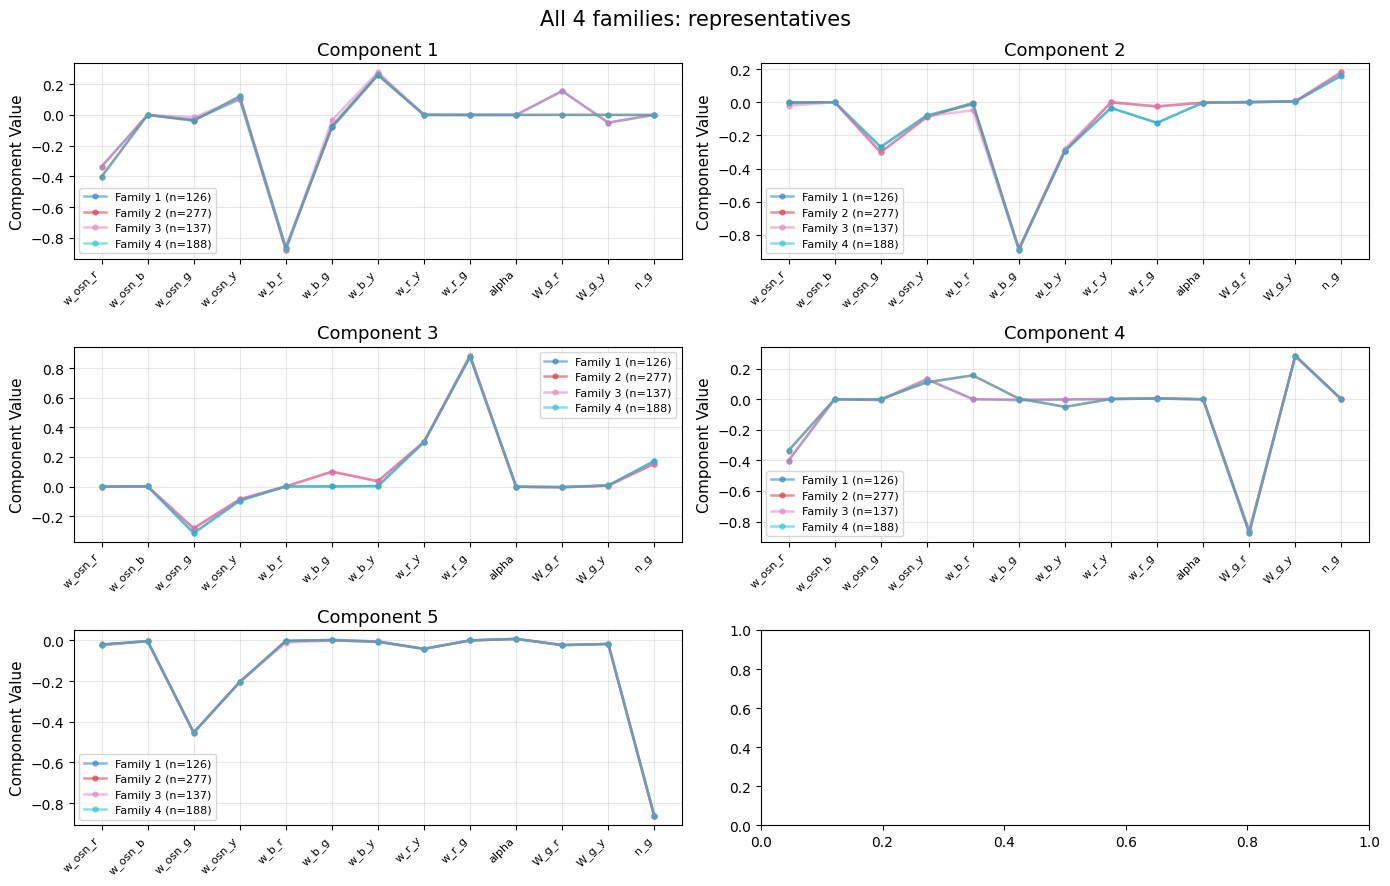

In [103]:

# Plot a representative from each family (aligned to family 0) 
# Only show families with at least a few members
min_family_size = 5
big_families = [f for f in families if len(f) >= min_family_size]
print(f"\nFamilies with ≥ {min_family_size} members: {len(big_families)}")

# Pick representative = lowest loss in each family (keep raw, unsorted)
reps_raw = []
for fam in big_families:
    losses_fam = loss_broad_all[fam]
    best_idx = fam[np.argmin(losses_fam)]
    reps_raw.append(U_broad[best_idx])
    print(f"  Family (n={len(fam)}): best loss = {losses_fam.min():.6f}")

# Sort ONLY Family 1 by sparsity — this defines the canonical column ordering
ref_sorted, ref_order = sort_by_sparsity(reps_raw[0])
reps_aligned = [ref_sorted]

# Align all other families to Family 1's sorted version (no independent sorting)
for k in range(1, len(reps_raw)):
    P_raw = ref_sorted.T @ reps_raw[k]  # (4, 4)
    _, col_ind = linear_sum_assignment(-np.abs(P_raw))
    aligned = reps_raw[k][:, col_ind]
    signs = np.sign(np.array([P_raw[r, c] for r, c in zip(range(5), col_ind)]))
    aligned = aligned * signs[None, :]
    reps_aligned.append(aligned)

# Overlay all family representatives
colors = plt.cm.tab10(np.linspace(0, 1, len(reps_aligned)))
fig, axes2 = plt.subplots(3, 2, figsize=(14, 9))
axes2 = axes2.flatten()

for i in range(5):
    for k, (rep, fam) in enumerate(zip(reps_aligned, big_families)):
        axes2[i].plot(rep[:, i], '.-', color=colors[k], lw=1.8, ms=7,
                      label=f'Family {k+1} (n={len(fam)})', alpha=0.5)
    axes2[i].set_xticks(range(len(param_labels)))
    axes2[i].set_xticklabels(param_labels, rotation=45, ha='right', fontsize=8)
    axes2[i].grid(True, alpha=0.3)
    axes2[i].set_ylabel('Component Value', fontsize=11)
    axes2[i].set_title(f'Component {i+1}', fontsize=13)
    axes2[i].legend(fontsize=8, loc='best')

plt.suptitle(f'All {len(big_families)} families: representatives',
             fontsize=15)
plt.tight_layout()
plt.show()


In [104]:
# save the 4 12x4 matrices
reps_aligned[0].shape
reps_aligned[1].shape
reps_aligned[2].shape
reps_aligned[3].shape

np.savez('reps_aligned.npz', reps_aligned=reps_aligned)


# Step in Δθ: how parameter perturbations affect output y

Steps each optimised θ along the sparse-rotation directions (U_A, U_B) and measures the relative change in the output y. Also compares true U directions against random directions.

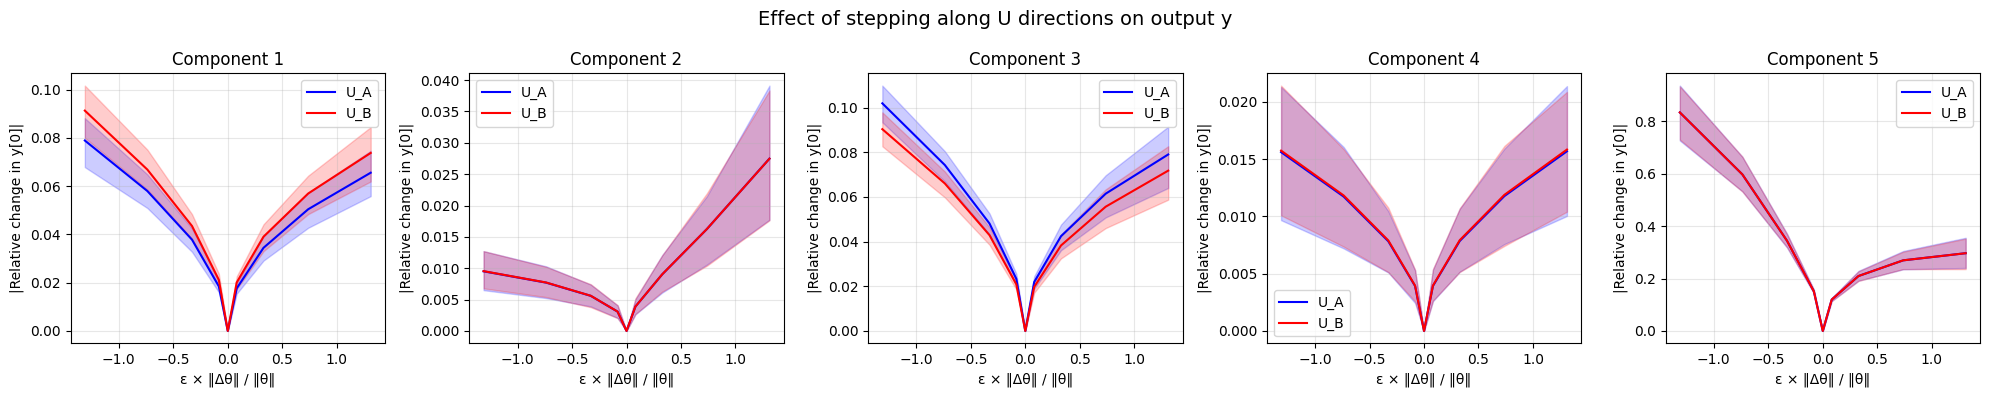

In [105]:
import seaborn as sns

# Use the sparse-rotation representatives computed in this notebook
# (rep_A_sorted and rep_B_aligned are defined in the cells above)
U1 = rep_A_sorted   # (13, 5)
U2 = rep_B_aligned  # (13, 5)

n_samples       = theta_opt.shape[0]
theta_opt_jnp   = jnp.array(theta_opt)
n_components    = U1.shape[1]  # 5

# Batch forward pass — n_g lives inside theta at index 12
def _mitral_single(theta):
    return mitral_output(theta, x, m, n_r, n_b, n_y)

mitral_output_batch = jax.jit(jax.vmap(_mitral_single))

# Baseline output at the unperturbed theta values
_, _, _, y_baseline = mitral_output_batch(theta_opt_jnp)
y_baseline = np.array(y_baseline)          # (n_samples, 2)

norm_theta_all  = np.linalg.norm(theta_opt, axis=1)
mean_norm_theta = np.mean(norm_theta_all)

# Epsilon grid
e = np.arange(-2, 2 + 0.2, 0.5)

# ── Plot: all U directions ────────────────────────────────────────────
Us       = [U1, U2]
u_labels = ['U_A', 'U_B']
u_colors = ['blue', 'red']

fig, axes = plt.subplots(1, n_components, figsize=(4 * n_components, 4))

for M, u_label, color in zip(Us, u_labels, u_colors):
    for k in range(n_components):
        true_dir = jnp.array(M[:, k])
        true_dir = true_dir / jnp.linalg.norm(true_dir)

        y_save = []
        for i in range(len(e)):
            theta_step = theta_opt_jnp + e[i] * true_dir
            _, _, _, y = mitral_output_batch(theta_step)
            y_save.append(np.array(y))
        y_array = np.array(y_save)  # (len(e), n_samples, 2)

        # Normalise step size by mean ||θ||
        theta_ratio = np.array(
            [e[i] * (np.linalg.norm(e[i] * true_dir) / mean_norm_theta)
             for i in range(len(e))]
        )

        y0_baseline = y_baseline[:, 0]
        rel0 = np.where(
            np.abs(y0_baseline) > 1e-12,
            (y_array[:, :, 0] - y0_baseline) / y0_baseline,
            y_array[:, :, 0] - y0_baseline,
        )
        abs_rel0              = np.abs(rel0)
        theta_ratio_expanded  = np.repeat(theta_ratio, n_samples)

        sns.lineplot(
            x=theta_ratio_expanded, y=abs_rel0.ravel(),
            ax=axes[k], color=color, label=u_label, errorbar=('ci', 95),
        )

for k in range(n_components):
    axes[k].set_xlabel('ε × ‖Δθ‖ / ‖θ‖')
    axes[k].set_ylabel('|Relative change in y[0]|')
    axes[k].set_title(f'Component {k + 1}')
    axes[k].grid(True, alpha=0.3)
    axes[k].legend()

plt.suptitle('Effect of stepping along U directions on output y', fontsize=14)
plt.tight_layout()
plt.show()

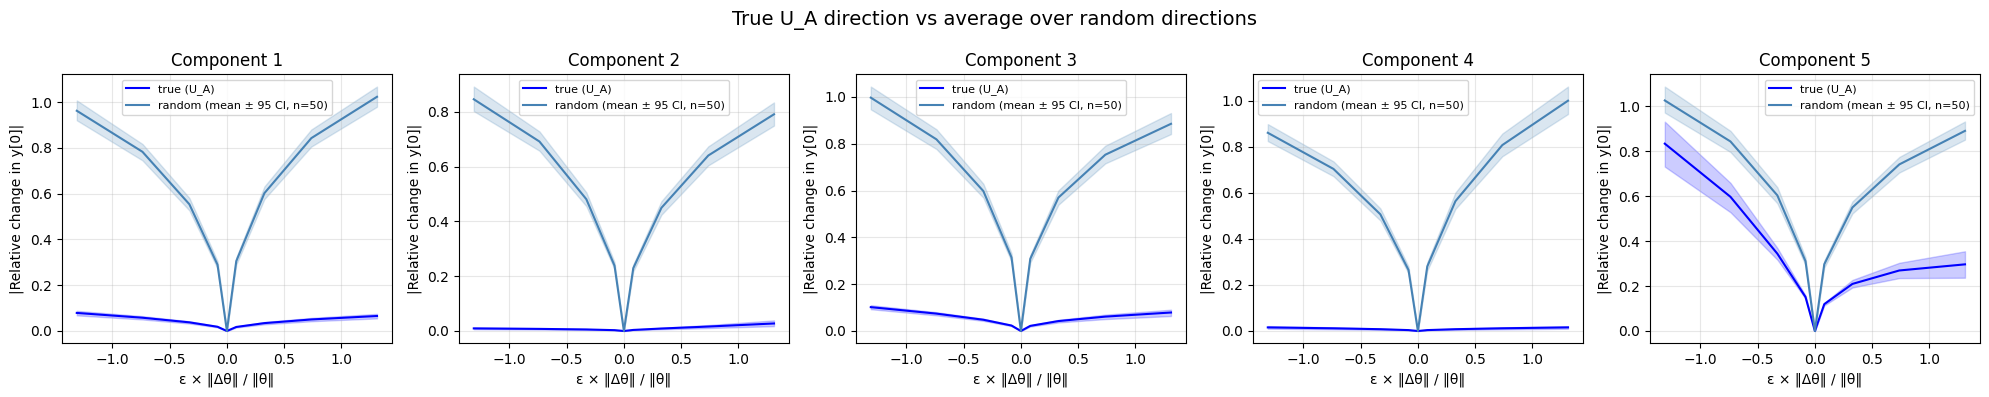

In [106]:
# ── Plot: true U_A direction vs average over many random directions ───
M            = U1
n_random     = 50   # number of random directions to average over
key          = jax.random.PRNGKey(42)

fig, ax = plt.subplots(1, n_components, figsize=(4 * n_components, 4))

for k in range(n_components):
    true_dir = jnp.array(M[:, k])
    true_dir = true_dir / jnp.linalg.norm(true_dir)

    # ── True direction ────────────────────────────────────────────────
    y_save = []
    for i in range(len(e)):
        theta_step = theta_opt_jnp + e[i] * true_dir
        _, _, _, y = mitral_output_batch(theta_step)
        y_save.append(np.array(y))
    y_array = np.array(y_save)  # (len(e), n_samples, 2)

    theta_ratio = np.array(
        [e[i] * (np.linalg.norm(e[i] * true_dir) / mean_norm_theta)
         for i in range(len(e))]
    )
    y0_baseline = y_baseline[:, 0]
    rel0 = np.where(
        np.abs(y0_baseline) > 1e-12,
        (y_array[:, :, 0] - y0_baseline) / y0_baseline,
        y_array[:, :, 0] - y0_baseline,
    )
    sns.lineplot(
        x=np.repeat(theta_ratio, n_samples), y=np.abs(rel0).ravel(),
        ax=ax[k], color='blue', label='true (U_A)', errorbar=('ci', 95),
    )

    # ── Many random directions → pool all trials together ─────────────
    # All unit-norm directions share the same theta_ratio values, so compute
    # it once. Reusing identical x-values across trials keeps seaborn's
    # aggregation smooth (no floating-point jitter between clusters).
    theta_ratio_rand = np.array(
        [e[i] * (abs(e[i]) / mean_norm_theta) for i in range(len(e))]
    )

    all_theta_ratio = []
    all_abs_rel     = []

    for _ in range(n_random):
        key, subkey = jax.random.split(key)
        rand_dir    = jax.random.normal(subkey, (M.shape[0],))
        rand_dir    = rand_dir / jnp.linalg.norm(rand_dir)

        y_save_r = []
        for i in range(len(e)):
            theta_step = theta_opt_jnp + e[i] * rand_dir
            _, _, _, y = mitral_output_batch(theta_step)
            y_save_r.append(np.array(y))
        y_array_r = np.array(y_save_r)  # (len(e), n_samples, 2)

        rel0_r = np.where(
            np.abs(y0_baseline) > 1e-12,
            (y_array_r[:, :, 0] - y0_baseline) / y0_baseline,
            y_array_r[:, :, 0] - y0_baseline,
        )
        all_theta_ratio.append(np.repeat(theta_ratio_rand, n_samples))
        all_abs_rel.append(np.abs(rel0_r).ravel())

    sns.lineplot(
        x=np.concatenate(all_theta_ratio),
        y=np.concatenate(all_abs_rel),
        ax=ax[k], color='steelblue',
        label=f'random (mean ± 95 CI, n={n_random})',
        errorbar=('ci', 95),
    )

    ax[k].set_xlabel('ε × ‖Δθ‖ / ‖θ‖')
    ax[k].set_ylabel('|Relative change in y[0]|')
    ax[k].set_title(f'Component {k + 1}')
    ax[k].grid(True, alpha=0.3)
    ax[k].legend(fontsize=8)

plt.suptitle('True U_A direction vs average over random directions', fontsize=14)
plt.tight_layout()
plt.show()